In [1]:
import numpy as np
import matplotlib.pyplot as plt 
from PIL import Image,ImageFilter,ImageEnhance
import os

In [2]:
healthy_path ="images/healthy"
tumor_path ="images/tumor"
print("Healthy images :",os.path.exists(healthy_path))
print("Tumor images :",os.path.exists(tumor_path))

Healthy images : True
Tumor images : True


In [3]:
healthy_files = os.listdir(healthy_path)
tumor_files = os.listdir(tumor_path)
print("healthy images :",healthy_files)
print("tumor images :",tumor_files)

healthy images : ['.ipynb_checkpoints', 'healthy (1).jpg', 'healthy (2).jpg', 'healthy (3).jpg', 'healthy (4).jpg', 'healthy (5).jpg']
tumor images : ['tumor (1).jpg', 'tumor (2).jpg', 'tumor (3).jpg', 'tumor (4).jpg', 'tumor (5).jpg']


In [4]:
healthy_files = [
    file for file in os.listdir(healthy_path)
    if file.lower().endswith((".jpg",".jpeg",".png"))
]
tumor_files =[
    file for file in os.listdir(tumor_path)
    if file.lower().endswith((".jpg",".jpeg",".png"))
]
print("Number of healthy images :",len(healthy_files))
print("Number of tumor images :",len(tumor_files))

Number of healthy images : 5
Number of tumor images : 5


In [5]:
healthy_image_path=os.path.join(healthy_path,healthy_files[0])
img=Image.open(healthy_image_path)
print(img.format)
print(img.size)
print(img.mode)

JPEG
(212, 236)
RGB


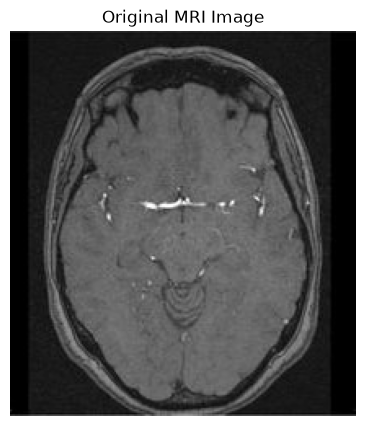

In [6]:
plt.figure(figsize=(5,5))
plt.imshow(img)
plt.title("Original MRI Image")
plt.axis("off")
plt.show()

In [7]:
gray_img = img.convert("L")
print("Original mode :", img.mode)
print("Grayscale mode :",gray_img.mode)

Original mode : RGB
Grayscale mode : L


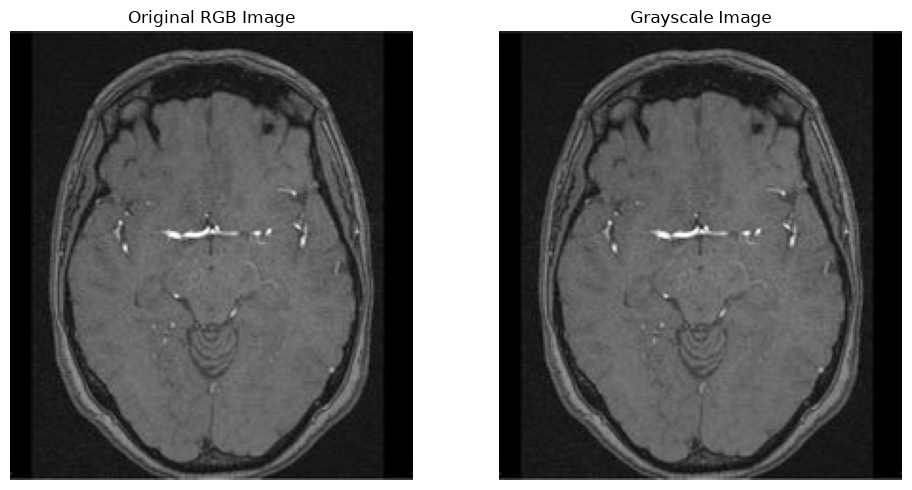

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(img)
axes[0].set_title("Original RGB Image")
axes[0].axis("off")

axes[1].imshow(gray_img, cmap="gray")
axes[1].set_title("Grayscale Image")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [9]:
resized_img = gray_img.resize((256, 256))

print("Original size:", gray_img.size)
print("Resized size:", resized_img.size)

Original size: (212, 236)
Resized size: (256, 256)


In [10]:
healthy_processed = []
tumor_processed = []

for filename in healthy_files:
    image_path = os.path.join(healthy_path, filename)
    image = Image.open(image_path)
    gray = image.convert("L")
    resized = gray.resize((256, 256))
    healthy_processed.append(resized)

for filename in tumor_files:
    image_path = os.path.join(tumor_path, filename)
    image = Image.open(image_path)
    gray = image.convert("L")
    resized = gray.resize((256, 256))
    tumor_processed.append(resized)

print("Healthy processed:", len(healthy_processed))
print("Tumor processed:", len(tumor_processed))

Healthy processed: 5
Tumor processed: 5


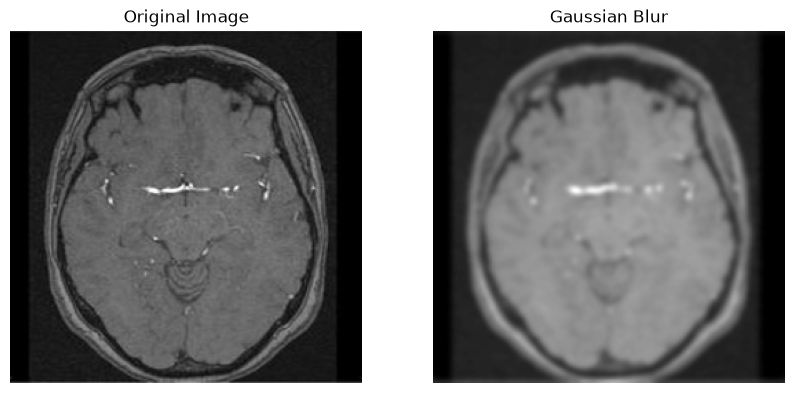

In [11]:
gaussian_img = healthy_processed [0].filter(ImageFilter.GaussianBlur(radius=2))
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(healthy_processed[0],cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(gaussian_img,cmap="gray")
plt.title("Gaussian Blur")
plt.axis("off")

plt.show()

In [12]:
median_img = healthy_processed[0].filter(ImageFilter.MedianFilter(size=3))

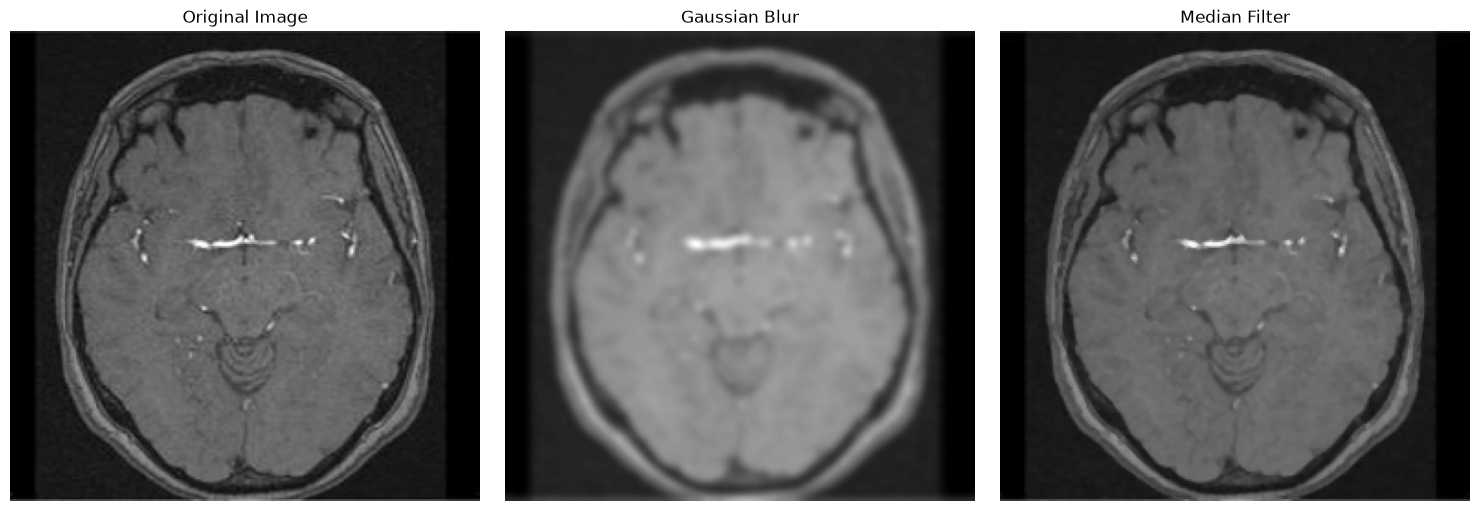

In [13]:
plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(healthy_processed[0],cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(gaussian_img,cmap="gray")
plt.title("Gaussian Blur")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(median_img,cmap="gray")
plt.title("Median Filter")
plt.axis("off")

plt.tight_layout()
plt.show()

In [14]:
enhancer = ImageEnhance.Contrast(healthy_processed[0])
enhance_img = enhancer.enhance(1.5)

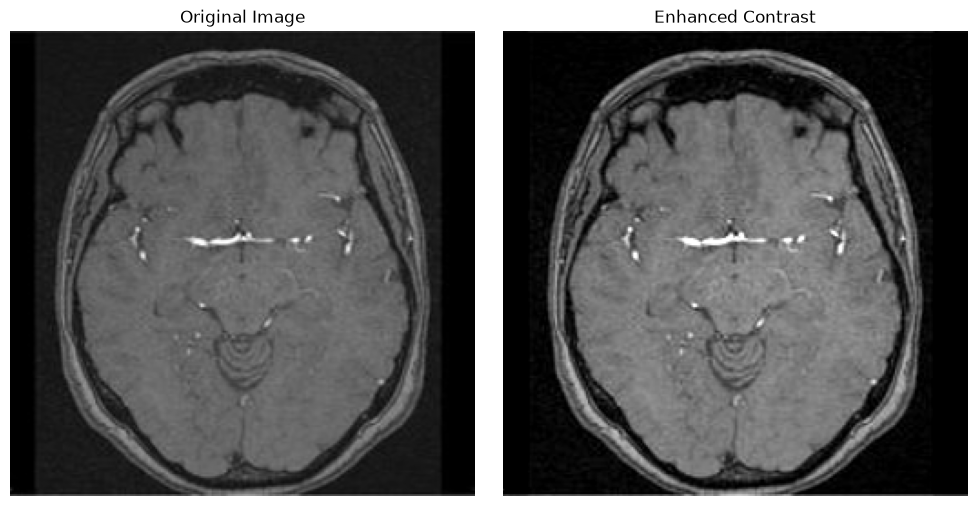

In [15]:
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(healthy_processed[0],cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(enhance_img,cmap="gray")
plt.title("Enhanced Contrast")
plt.axis("off")

plt.tight_layout()
plt.show()

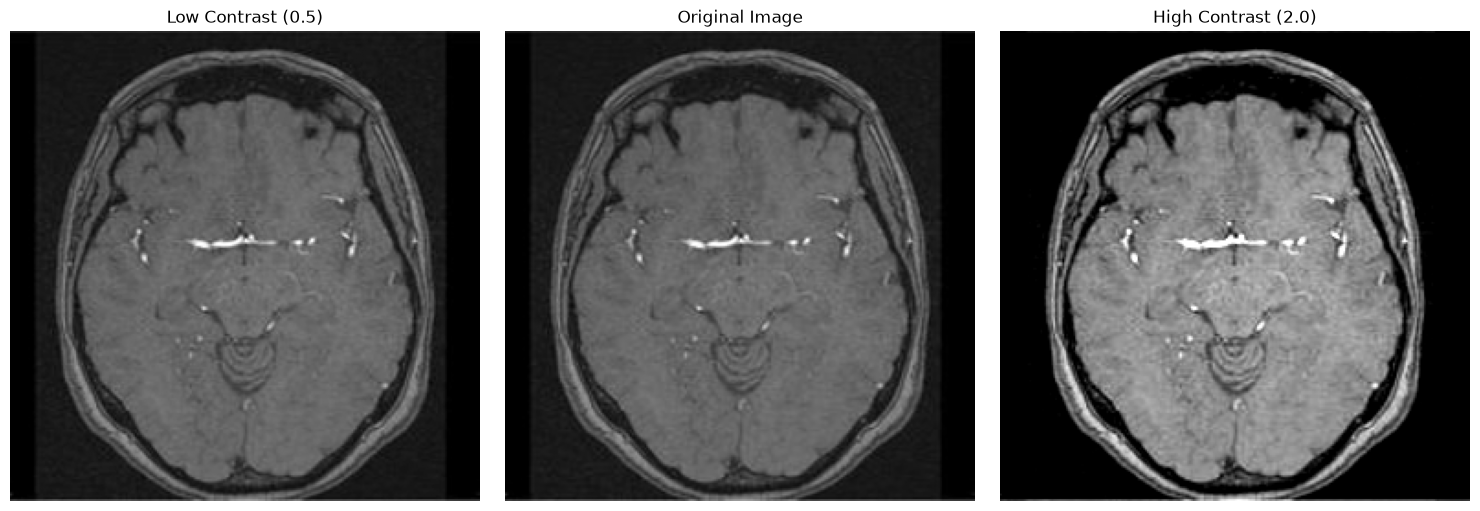

In [16]:
low_contrast =enhancer.enhance(0.5)
high_contrast =enhancer.enhance(2.0)

plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(low_contrast,cmap="gray")
plt.title("Low Contrast (0.5)")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(healthy_processed[0],cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(high_contrast,cmap="gray")
plt.title("High Contrast (2.0)")
plt.axis("off")

plt.tight_layout()
plt.show()

In [17]:
os.makedirs("results",exist_ok=True)

In [18]:
healthy_processed[0].save("results/healthy_grayscale_resized.jpg")

In [19]:
gaussian_img.save("results/healthy_gaussian_blur.jpg")

In [20]:
median_img.save("results/healthy_median_filter.jpg")

In [21]:
enhance_img.save("results/healthy_contrast_enhanced.jpg")

In [22]:
print(os.listdir("results"))

['.ipynb_checkpoints', 'contrast', 'gaussian', 'grayscale_resized', 'healthy_contrast_enhanced.jpg', 'healthy_contrust_enhanced.jpg', 'healthy_gaussian_blur.jpg', 'healthy_grayscale_resized.jpg', 'healthy_median_filter.jpg', 'median']


In [23]:
results_summary ={
    "Method":[
        "Grayscale + Resize",
        "gaussian Blur",
        "Median Filter",
        "Contrast Enhancement"
    ],
    "Output File":[
        "healthy_grayscale_resized.jpg",
        "healthy_gaussian_blur.jpg",
        "healthy_median_filter.jpg",
        "healthy_contrast_enhanced.jpg"
    ]
}
import pandas as pd
results_df = pd.DataFrame(results_summary)
results_df

,Method,Output File
0,Grayscale + Resize,healthy_grayscale_resized.jpg
1,gaussian Blur,healthy_gaussian_blur.jpg
2,Median Filter,healthy_median_filter.jpg
3,Contrast Enhancement,healthy_contrast_enhanced.jpg


Image size: (256, 256)


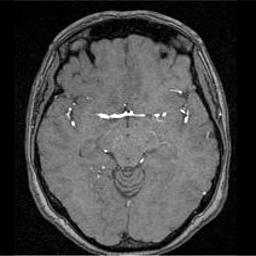

In [24]:
saved_img=Image.open("results/healthy_contrast_enhanced.jpg")
print("Image size:",saved_img.size)
display(saved_img)

In [25]:
os.makedirs("results/grayscale_resized",exist_ok=True)
os.makedirs("results/gaussian",exist_ok=True)
os.makedirs("results/median",exist_ok=True)
os.makedirs("results/contrast",exist_ok=True)

In [26]:
healthy_gaussian = []
tumor_gaussian = []
for image in healthy_processed:
    blurred = image.filter(ImageFilter.GaussianBlur(radius=2))
    healthy_gaussian.append(blurred)

for image in tumor_processed:
    blurred = image.filter(ImageFilter.GaussianBlur(radius=2))
    tumor_gaussian.append(blurred)

print("Healthy Image :",len(healthy_gaussian))
print("tumor Image :",len(tumor_gaussian))

Healthy Image : 5
tumor Image : 5


In [27]:
for i,image in enumerate(healthy_gaussian,start=1):
    image.save(f"results/gaussian/healthy_{i}.jpg")
for i,image in enumerate(tumor_gaussian,start=1):
    image.save(f"results/gaussian/tumor_{i}.jpg")

In [28]:
print(os.listdir("results/gaussian"))

['healthy_1.jpg', 'healthy_2.jpg', 'healthy_3.jpg', 'healthy_4.jpg', 'healthy_5.jpg', 'tumor_1.jpg', 'tumor_2.jpg', 'tumor_3.jpg', 'tumor_4.jpg', 'tumor_5.jpg']


In [29]:
healthy_median = []
tumor_median = []
for image in healthy_processed:
    filtered = image.filter(ImageFilter.MedianFilter(size=3))
    healthy_median.append(filtered)

for image in tumor_processed:
    filtered = image.filter(ImageFilter.MedianFilter(size=3))
    tumor_median.append(filtered)

print("Healthy Image :",len(healthy_median))
print("Tumor Image :",len(tumor_median))

Healthy Image : 5
Tumor Image : 5


In [30]:
for i,image in enumerate(healthy_median,start=1):
    image.save(f"results/median/healthy_{i}.jpg")
    
for i,image in enumerate(tumor_median,start=1):
    image.save(f"results/median/tumor_{i}.jpg")
    
print(os.listdir("results/median"))

['healthy_1.jpg', 'healthy_2.jpg', 'healthy_3.jpg', 'healthy_4.jpg', 'healthy_5.jpg', 'tumor_1.jpg', 'tumor_2.jpg', 'tumor_3.jpg', 'tumor_4.jpg', 'tumor_5.jpg']


In [31]:
healthy_contrast = []
tumor_contrast = []

contrast_factor = 1.5

for image in healthy_processed:
    enhancer = ImageEnhance.Contrast(image)
    enhanced = enhancer.enhance(contrast_factor)
    healthy_contrast.append(enhanced)

for image in tumor_processed:
    enhancer = ImageEnhance.Contrast(image)
    enhanced = enhancer.enhance(contrast_factor)
    tumor_contrast.append(enhanced)

print("Healthy Image :",len(healthy_contrast))
print("Tumor Image :",len(tumor_contrast))


Healthy Image : 5
Tumor Image : 5


In [32]:
for i,image in enumerate(healthy_contrast,start=1):
    image.save(f"results/contrast/healthy_{i}.jpg")

for i,image in enumerate(tumor_contrast,start=1):
    image.save(f"results/contrast/tumor_{i}.jpg")

print(os.listdir("results/contrast"))

      

['healthy_1.jpg', 'healthy_2.jpg', 'healthy_3.jpg', 'healthy_4.jpg', 'healthy_5.jpg', 'tumor_1.jpg', 'tumor_2.jpg', 'tumor_3.jpg', 'tumor_4.jpg', 'tumor_5.jpg']


In [33]:
for i,image in enumerate(healthy_processed,start=1):
    image.save(f"results/grayscale_resized/healthy{i}.jpg")

for i,image in enumerate(tumor_processed,start=1):
    image.save(f"results/grayscale_resized/tumor{i}.jpg")

print(os.listdir("results/grayscale_resized"))

['healthy1.jpg', 'healthy2.jpg', 'healthy3.jpg', 'healthy4.jpg', 'healthy5.jpg', 'tumor1.jpg', 'tumor2.jpg', 'tumor3.jpg', 'tumor4.jpg', 'tumor5.jpg']


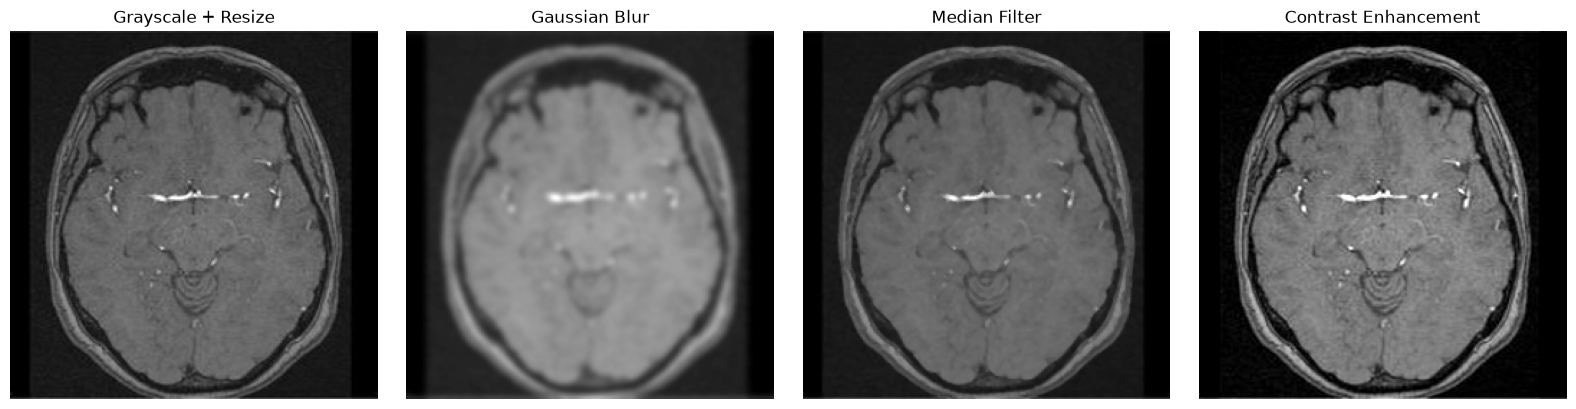

In [34]:
plt.figure(figsize=(16,4))

images = [
    healthy_processed[0],
    healthy_gaussian[0],
    healthy_median[0],
    healthy_contrast[0]
]
titles =[
    "Grayscale + Resize",
    "Gaussian Blur",
    "Median Filter",
    "Contrast Enhancement"
]

for i in range(4):
    plt.subplot(1,4,i+1)
    plt.imshow(images[i],cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

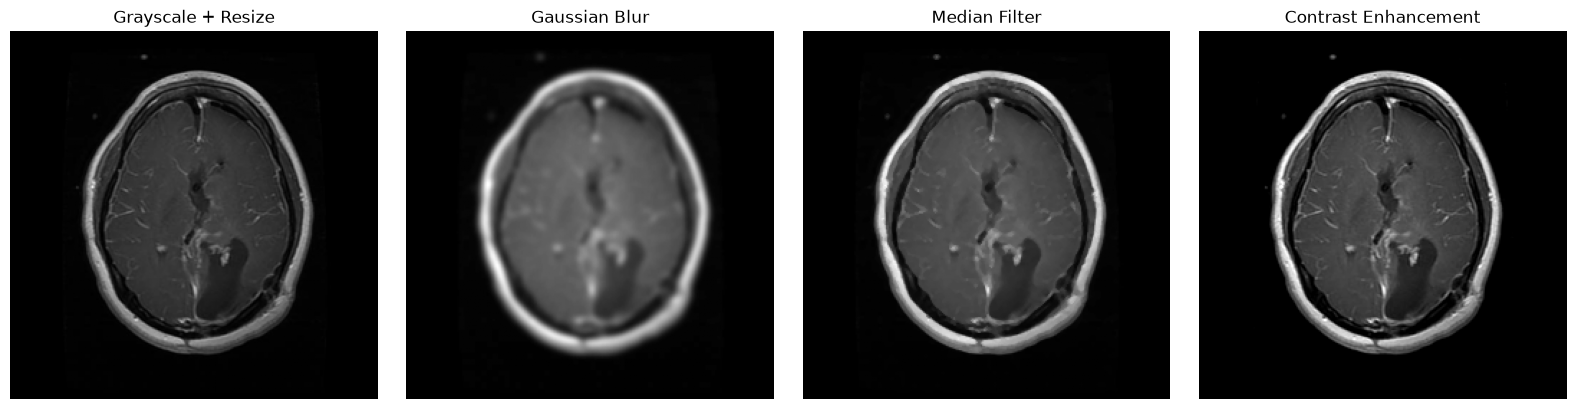

In [35]:
plt.figure(figsize=(16,4))

images =[
    tumor_processed[0],
    tumor_gaussian[0],
    tumor_median[0],
    tumor_contrast[0]
]
titles = [
    "Grayscale + Resize",
    "Gaussian Blur",
    "Median Filter",
    "Contrast Enhancement"
]

for i in range(4):
    plt.subplot(1,4,i+1)
    plt.imshow(images[i],cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()
    

In [36]:
results_analysis ={
    "Method" :[
        "Grayscale + Resize",
    "Gaussian Blur",
    "Median Filter",
    "Contrast Enhancement"
    ],
    "Advantages":[
        "Simplifies image representatian and standardizes size",
        "Reduces image noise and smooths the image",
        "Can Reduce noise while preserving edges",
        "Improves visual contrast between bright and dark regions"
    ],
    "Limitations" :[
        "May remove color information",
        "May blur edges and fine details",
        "may remove some small details",
        "Excessive enhancement may cause detail loss"
    ]
}
analysis_df = pd.DataFrame(results_analysis)
analysis_df
        

    

,Method,Advantages,Limitations
0,Grayscale + Resize,Simplifies image representatian and standardiz...,May remove color information
1,Gaussian Blur,Reduces image noise and smooths the image,May blur edges and fine details
2,Median Filter,Can Reduce noise while preserving edges,may remove some small details
3,Contrast Enhancement,Improves visual contrast between bright and da...,Excessive enhancement may cause detail loss


In [37]:
analysis_df.loc[2,"Observed Results"] = (
    "Preserved more visible details than gaussian Blur"
    "in the selected sample image." 
)
analysis_df.loc[1,"Observed Results"] = (
    "Produced srtonger smoothing and blurred some visible details."
)
analysis_df.loc[3,"Observed Results"] = (
    "Improved visual contrast, making some regions mor distinguishable."
)
analysis_df.loc[0,"Observed Results"] = (
    "Provided a standardized grayscale image with a fixed size."
)
analysis_df


,Method,Advantages,Limitations,Observed Results
0,Grayscale + Resize,Simplifies image representatian and standardiz...,May remove color information,Provided a standardized grayscale image with a...
1,Gaussian Blur,Reduces image noise and smooths the image,May blur edges and fine details,Produced srtonger smoothing and blurred some v...
2,Median Filter,Can Reduce noise while preserving edges,may remove some small details,Preserved more visible details than gaussian B...
3,Contrast Enhancement,Improves visual contrast between bright and da...,Excessive enhancement may cause detail loss,"Improved visual contrast, making some regions ..."


In [38]:
for folder in [
    "grayscale_resized",
    "gaussian",
    "median",
    "contrast"
]:
        path= os.path.join("results",folder)
        files = os.listdir(path)

        print(folder,":",len(files),"files")

grayscale_resized : 10 files
gaussian : 10 files
median : 10 files
contrast : 10 files


In [39]:
print("Image size :", healthy_processed[0].size)
print("Image mode :", healthy_processed[0].mode)
print("Number of healthy images:",len(healthy_processed))
print("Number of tumor images:",len(tumor_processed))

Image size : (256, 256)
Image mode : L
Number of healthy images: 5
Number of tumor images: 5
